# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [30]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [31]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [32]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


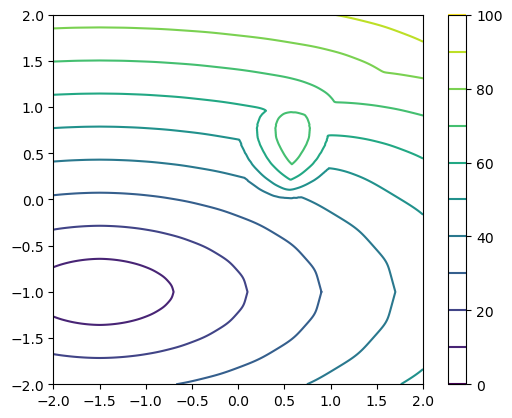

In [33]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [34]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


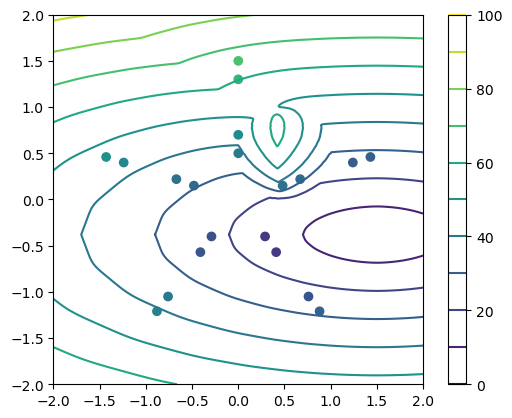

In [35]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [36]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

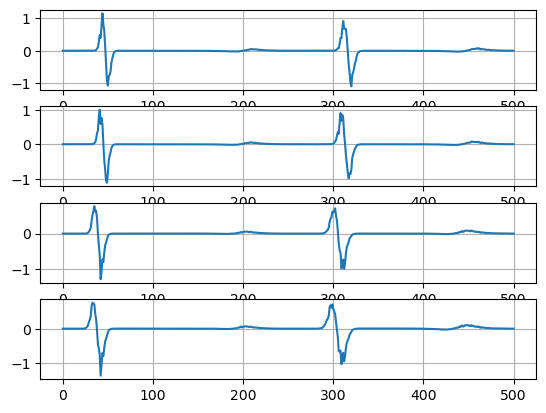

In [37]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [38]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy') -2.0
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [39]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
from tqdm import tqdm  # <-- IMPORTANTE: Aggiunto per la barra di progresso
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
X_mesh_vel, Y_mesh_vel = np.meshgrid(np.linspace(-2.0, 2.0, 201), np.linspace(-2.0, 2.0, 201))
X_mesh_100, Y_mesh_100 = np.meshgrid(np.linspace(-2.0, 2.0, 101), np.linspace(-2.0, 2.0, 101))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

meas_indices = []
for j in range(5):
    for i in range(4):
        MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
        meas_indices.append((i_sel, j_sel))

meas_indices_vel = []
for j in range(5):
    for i in range(4):
        MeasMat_vel = (X_mesh_vel - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_vel - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_vel.argmin(), MeasMat_vel.shape)
        meas_indices_vel.append((i_sel, j_sel))

meas_indices_100 = []
for j in range(5):
    for i in range(4):
        MeasMat_100 = (X_mesh_100 - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh_100 - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat_100.argmin(), MeasMat_100.shape)
        meas_indices_100.append((i_sel, j_sel))

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = np.load('checkpoint2anisotropy.npy')

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] 

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (CORRETTA)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Se la correlazione era negativa, significa che i 4 sensori di ogni spline
    # nel dataset sono invertiti rispetto a Spline_spacing.
    
    t_beat1_ordered = []
    t_beat2_ordered = []
    
    for s in range(5): # Per ogni spline
        # Prendi i 4 tempi della spline s
        spline_times = raw_timings[s*4 : (s+1)*4]
        
        # PROVA A INVERTIRE QUI: 
        # Se il dataset è [Lontano -> Vicino], invertiamo per farlo diventare [Vicino -> Lontano]
        spline_times = spline_times[::-1] 
        
        for t in spline_times:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])
            
    measured_times_beat1.append(np.array(t_beat1_ordered, dtype=float))
    measured_times_beat2.append(np.array(t_beat2_ordered, dtype=float))


In [40]:
# ==========================================
# 4. FUNZIONE OBIETTIVO CON VELOCITÀ SFUMATA (TANH)
# ==========================================
def objective_velocities(velocities):
    v_base, v_slow = velocities
    total_mse = 0.0
    
    # Parametro di ripidezza del bordo (k)
    # 50.0 rende il bordo netto ma matematicamente derivabile
    k = 50.0 
    
    for idx in range(5):
        xc, yc, r = reference_targets[idx]
        a_ratio = a_ratios_training[idx]**2
        
        # 1. Costruzione tensore di diffusione (Anisotropia)
        theta0 = np.pi/2 # fiber_theta assumed 0
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # 2. CREAZIONE CAMPO VELOCITÀ SFUMATO (Sostituisce il lambda)
        # Calcoliamo la distanza di ogni punto della mesh dal centro dell'ischemia
        # dist = np.sqrt((X_mesh_vel - xc)**2 + (Y_mesh_vel - yc)**2)
        
        # Funzione peso basata su tanh: 0 all'interno, 1 all'esterno
        # weight = 0.5 * (1 + np.tanh(k * (dist - r)))
        
        # Matrice delle velocità (vettorializzata, molto più veloce del lambda)
        # speed_grid = v_slow + weight * (v_base - v_slow)

        speed_field = lambda x, y: v_slow + 0.5 * (1 + np.tanh(k * (np.hypot(x - xc, y - yc) - r))) * (v_base - v_slow)
        
        # NOTA: anisotropic_FMM_GPT deve ora accettare 'speed_grid' (matrice) 
        # invece di 'speed_field' (funzione). 
        # Se la tua FMM accetta solo funzioni, passagli: lambda x, y: speed_grid
        
        # --- SIMULAZIONE BATTITO 1 ---
        x0, y0 = impulse_sites[idx][0]
        t0 = starting_times[idx][0]/1000.0
        
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        sim_times1 = sim_times1 - np.min(sim_times1)
        meas_times1 = measured_times_beat1[idx]
        meas_times1 = meas_times1 - np.nanmin(meas_times1)
        
        mask1 = ~np.isnan(meas_times1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_times1[mask1])**2)
            
        # --- SIMULAZIONE BATTITO 2 ---
        x1, y1 = impulse_sites[idx][1]
        t1 = starting_times[idx][1]/1000.0
        
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        sim_times2 = sim_times2 - np.min(sim_times2)
        meas_times2 = measured_times_beat2[idx]
        meas_times2 = meas_times2 - np.nanmin(meas_times2)
        
        mask2 = ~np.isnan(meas_times2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_times2[mask2])**2)
        
    return total_mse

In [41]:
# ==========================================
# 5. AVVIO OTTIMIZZAZIONE
# ==========================================
initial_guess = [80.0, 20.0] 
bounds = [(40.0, 150.0), (5.0, 40.0)] 

print("Inizio calibrazione delle velocità (su 2 battiti per paziente)...")
pbar = tqdm(desc="Valutazioni Funzione Obiettivo", unit="eval")
# Funzione wrapper per aggiornare la barra ad ogni chiamata
def objective_with_pbar(velocities):
    pbar.update(1)
    # Mostra i valori correnti in tempo reale nella barra
    pbar.set_postfix({"v_base": f"{velocities[0]:.3f}", "v_slow": f"{velocities[1]:.3f}"})
    return objective_velocities(velocities)

result = minimize(objective_with_pbar, initial_guess, method='Nelder-Mead', bounds=bounds, options={'xatol': 1.0, 'fatol': 0.1})
pbar.close()

if result.success:
    print(f"\n✅ Ottimizzazione convergente!")
    print(f"Velocità tessuto sano (v_base): {result.x[0]:.2f}")
    print(f"Velocità tessuto lento (v_slow): {result.x[1]:.2f}")
else:
    print("\n❌ L'ottimizzatore non ha trovato un minimo:", result.message)

Inizio calibrazione delle velocità (su 2 battiti per paziente)...


Valutazioni Funzione Obiettivo: 5eval [17:22, 208.41s/eval, v_base=86.000, v_slow=18.000]
Valutazioni Funzione Obiettivo: 24eval [10:30, 26.29s/eval, v_base=67.681, v_slow=19.729]


✅ Ottimizzazione convergente!
Velocità tessuto sano (v_base): 67.96
Velocità tessuto lento (v_slow): 19.80


In [42]:
# ==========================================
# 6. SALVATAGGIO DELLE VELOCITÀ STIMATE
# ==========================================
if result.success:
    EST_V_BASE = result.x[0]
    EST_V_SLOW = result.x[1]

sim_rel [3.14501151e+01 3.38620357e+01 4.18547945e+01 4.45666152e+01
 4.80538385e+01 4.84426972e+01 6.43744148e+01 7.02179407e+01
 5.46240539e+01 4.95426650e+01 4.03565895e+01 4.29266074e+01
 1.39392024e+01 9.63297419e+00 2.33973206e-03 0.00000000e+00
 1.48177086e+01 1.10232115e+01 3.66897189e+00 4.11472193e+00]
meas_rel [28. 29. 35. 38. 47. 51. 60. 64. 41. 44. 39. 39. 13.  9.  0.  0. 13.  9.
  3.  4.]
21.691772500377677
sim_rel2 [25.34955426 28.29131263 37.79349746 40.89991762 40.99569591 41.38455453
 57.31627217 63.15979809 44.55523109 39.48960581 30.34167752 32.97273337
  5.08411423  0.         11.66659836 16.72399555 11.46180112 11.33568638
 20.79721613 25.14034294]
meas_rel2 [39. 39. 47. 50. 61. 68. 77. 82. 49. 49. 46. 46. 14.  0. 14. 20. 17. 16.
 24. 28.]
150.5583768576504
--- VERIFICA SPAZIALE SCENARIO 1 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            38.00 |                    1.2341
      1 

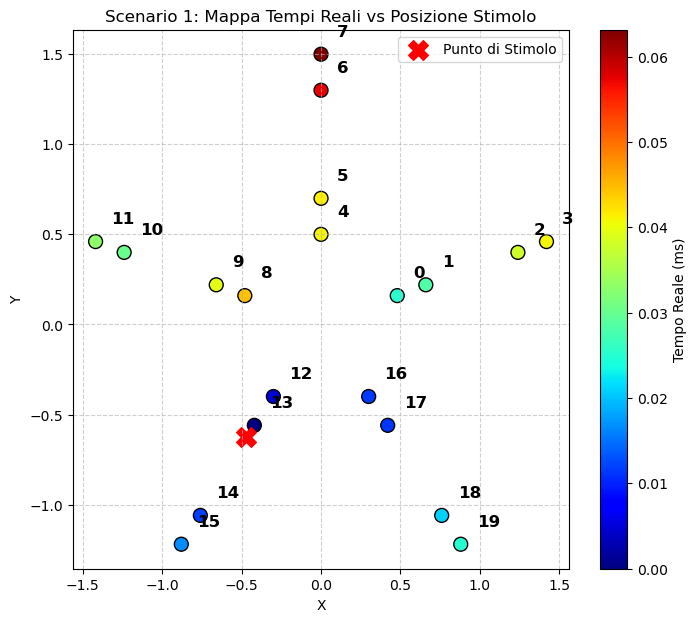

sim_rel [ 5.74336458 15.9930418  28.7621733  29.31669582 13.54046264 22.32859202
 48.76653206 57.5863855   0.          3.7124626  15.33696751 19.10777166
  3.98750616 11.28958626 33.96514216 41.25626414  5.40475577 12.60645449
 35.10100995 42.37780662]
meas_rel [ 8. 14. 35. 39. 13. 20. 42. 49.  0.  4. 14. 17.  4. 10. 29. 35.  6. 11.
 30. 36.]
20.418457640178516
sim_rel2 [ 67.16681663  77.76882231  79.36922148  82.28633744  76.71302892
  85.44596702 111.74694556 120.52533273  60.94726603  63.42634871
  71.6623343   74.59189486  36.78507815  29.50766256   6.90943116
   0.          39.3310787   33.62049779  20.06018073  18.33293429]
meas_rel2 [ 71.  78.  93.  90.  74.  83. 106. 113.  59.  62.  69.  72.  37.  30.
   8.   0.  40.  36.  24.  22.]
20.96179838111876
--- VERIFICA SPAZIALE SCENARIO 2 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            17.00 |                    2.0270
      1 |            23.00 | 

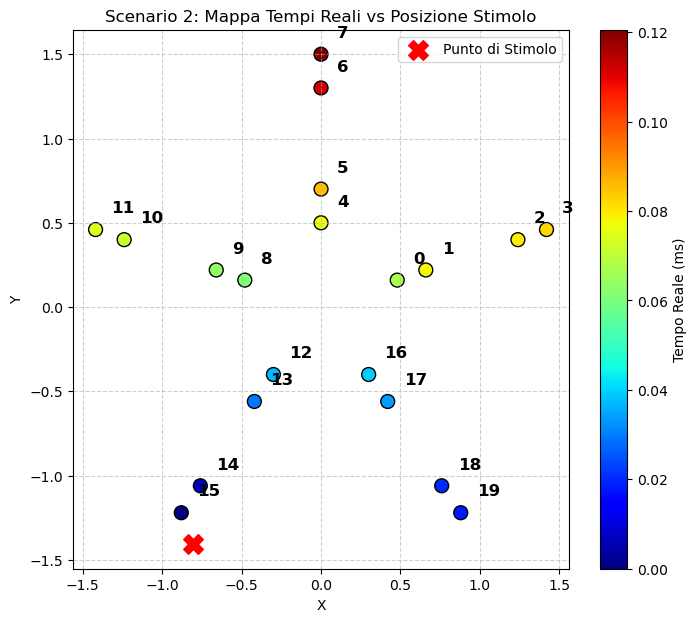

sim_rel [ 9.92762712 11.79999234 18.68652311 21.06890898 13.65680009 16.5994236
 25.42757493 28.37031258 10.36690432 12.35182612 19.46595054 21.9248088
  1.73843476  0.72217965  1.38160454  3.13206111  1.2409874   0.
  0.21704429  1.96462324]
meas_rel [ 8. 10. 16. 18. 12. 15. 22. 24. 10. 13. 20. 23.  3.  4.  5.  6.  1.  0.
  1.  2.]
4.803211163373557
sim_rel2 [ 2.60204401  4.56655287 12.51250074 15.18631125  9.20015652 11.81125805
 20.10836278 22.94235551 11.14902578 13.9365016  22.86012792 25.65705385
  7.57189207 10.09166078 18.29023623 21.13287191  0.          1.82177369
 10.48668605 13.40522937]
meas_rel2 [ 6.  8. 17. 20. 13. 16. 25. 28. 15. 18. 28. 31. 12. 17. 30. 32.  0.  4.
 14. 17.]
29.35001485759458
--- VERIFICA SPAZIALE SCENARIO 3 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            20.00 |                    0.3864
      1 |            22.00 |                    0.5073
      2 |            28.0

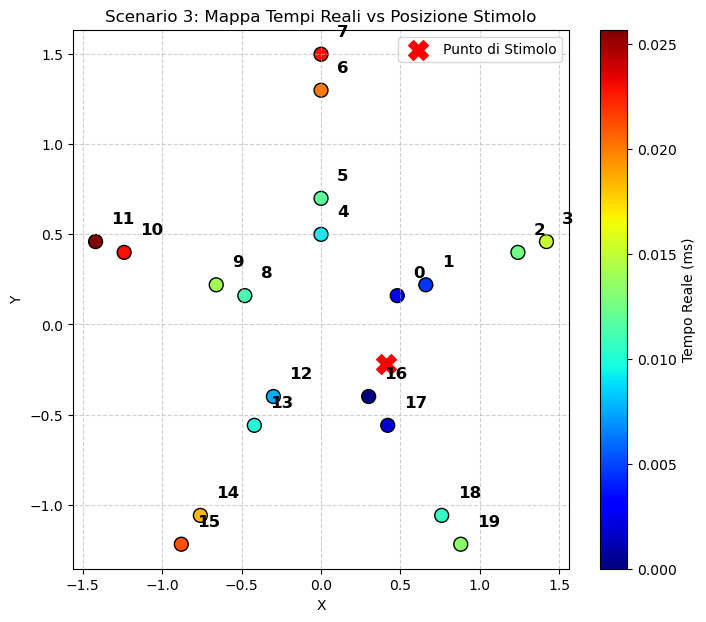

sim_rel [15.81655916 17.78593149 24.71635588 27.08863762 18.73297853 21.65573349
 30.45316538 33.39180268 13.98922854 15.50165449 21.40003356 23.52378525
  5.39207076  3.44689968  0.          0.30464732  7.18467136  6.05583932
  5.06540658  5.88159221]
meas_rel [17. 17. 22. 24. 18. 20. 27. 30. 13. 14. 19. 20.  5.  4.  0.  0.  8.  6.
  5.  6.]
3.4146634550095443
sim_rel2 [19.24730091 18.84410244 19.43965778 20.38039588 27.28143679 29.72644054
 37.45480065 40.08617773 28.35930201 30.95976064 39.3387023  42.0123512
 21.20647851 21.59293001 24.01115412 25.42031245 14.21610813 11.29556289
  2.71641718  0.        ]
meas_rel2 [22. 21. 22. 23. 31. 34. 41. 43. 32. 34. 42. 44. 23. 23. 25. 27. 18. 13.
  3.  0.]
6.914844670470648
--- VERIFICA SPAZIALE SCENARIO 4 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            33.00 |                    1.7410
      1 |            33.00 |                    1.7189
      2 |      

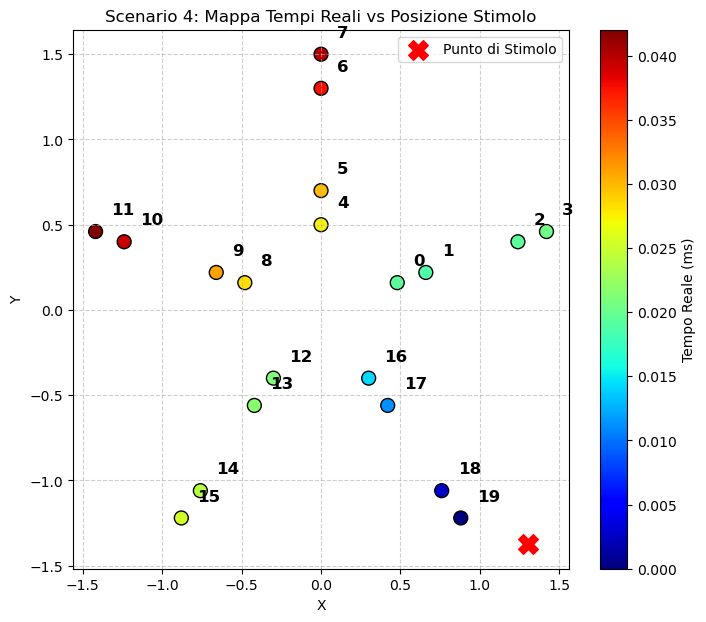

sim_rel [16.04568146 13.36446363  5.83531745  3.75120941 11.60299919  7.43762007
  0.          0.61983278 23.84381336 24.35090325 27.50197294 28.74407431
 36.00282274 40.99472051 56.40712888 61.42630664 32.33399846 36.2629281
 49.61887261 53.80378099]
meas_rel [12. 10.  4.  2.  9.  6.  0.  0. 19. 19. 22. 23. 29. 33. 46. 50. 29. 37.
 49. 47.]
28.443338694954114
sim_rel2 [34.4092842  37.46308495 47.15288899 50.27123041 39.46091208 44.91511365
 61.69812406 67.38397606 27.49932738 28.41329858 32.61656036 34.55440999
 14.2571908   9.54325168  0.          1.92008086 20.74656143 19.67510535
 21.74878753 24.47690227]
meas_rel2 [32. 35. 44. 48. 37. 41. 57. 62. 25. 26. 31. 32. 12.  7.  0.  4. 22. 25.
 33. 31.]
16.778931553676088
--- VERIFICA SPAZIALE SCENARIO 5 ---
Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)
--------------------------------------------------
      0 |            32.00 |                    2.0164
      1 |            30.00 |                    2.2002
      2 |     

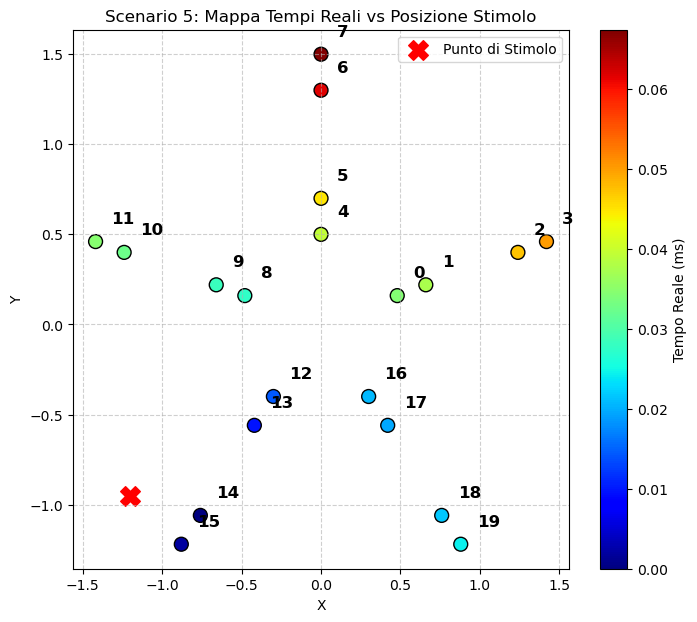

In [43]:
a_ratios_training = np.load('checkpoint2anisotropy.npy')
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy')
starting_times = np.load('checkpoint2starting.npy') 
reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]]

for idx in range(5):
    a_ratio = a_ratios_training[idx]**2
    xc, yc, r = reference_targets[idx]

    theta0 = np.pi/2 
    a = np.array([np.cos(theta0), np.sin(theta0)])
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
    D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
    D_inv = np.linalg.inv(D)
    sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]

    speed_field = lambda x, y: EST_V_SLOW if (x - xc)**2 + (y - yc)**2 <= r**2 else EST_V_BASE
    signals_event = signals[idx, :, :]
    x_0, y_0 = impulse_sites[idx][0]
    x_1, y_1 = impulse_sites[idx][1]
    t_0 = starting_times[idx][0]/1000
    t_1 = starting_times[idx][1]/1000

    # Simulazione BATTITO 1
    sim_beat1 = anisotropic_FMM_GPT(
        x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )

    sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        
    # Simulazione BATTITO 2
    sim_beat2 = anisotropic_FMM_GPT(
        x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
        sigma_11, sigma_12, sigma_22
    )

    sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])

    meas_rel = measured_times_beat1[idx]
    meas_rel = meas_rel - np.min(meas_rel)
    sim_times1 = sim_times1 - np.min(sim_times1)
    print('sim_rel', sim_times1*1e3)
    print('meas_rel', meas_rel)
    print(np.mean((sim_times1*1e3 - meas_rel)**2))

    meas_rel2 = measured_times_beat2[idx]
    meas_rel2 = meas_rel2 - np.min(meas_rel2)
    sim_times2 = sim_times2 - np.min(sim_times2)
    print('sim_rel2', sim_times2*1e3)
    print('meas_rel2', meas_rel2)
    print(np.mean((sim_times2*1e3 - meas_rel2)**2))

    x_stim, y_stim = impulse_sites[idx][1]

    # 2. Tempi reali (normalizzati)
    meas_rel = measured_times_beat1[idx] 

    # 3. Calcoliamo la distanza EUCLIDEA pura tra stimolo e sensori sulla tua mesh
    # Usiamo le coordinate estratte tramite i tuoi meas_indices_vel
    distanze_mesh = []
    for i, j in meas_indices_vel:
        d = np.sqrt((X_mesh_vel[i, j] - x_stim)**2 + (Y_mesh_vel[i, j] - y_stim)**2)
        distanze_mesh.append(d)

    distanze_mesh = np.array(distanze_mesh)

    # 4. Confronto
    print(f"--- VERIFICA SPAZIALE SCENARIO {idx+1} ---")
    print("Sensore | Tempo Reale (ms) | Distanza dallo Stimolo (mesh)")
    print("-" * 50)
    for s in range(20):
        print(f"{s:7d} | {meas_rel[s]:16.2f} | {distanze_mesh[s]:25.4f}")

    # 5. Correlazione
    correlation = np.corrcoef(meas_rel2, distanze_mesh)[0, 1]
    print("-" * 50)
    print(f"Correlazione Tempo/Distanza: {correlation:.4f}")

    # Estraiamo gli indici i e j dalla tua lista di tuple
    meas_indices_vel_i = [idx[0] for idx in meas_indices_vel]
    meas_indices_vel_j = [idx[1] for idx in meas_indices_vel]

    plt.figure(figsize=(8,7))

    # Disegniamo i sensori colorandoli in base al tempo reale di attivazione
    sc = plt.scatter(X_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    Y_mesh_vel[meas_indices_vel_i, meas_indices_vel_j], 
                    c=sim_times2, cmap='jet', s=100, edgecolors='k')
    # Disegniamo il punto di stimolo (focal point)
    plt.scatter(x_stim, y_stim, color='red', marker='X', s=200, label='Punto di Stimolo')

    # Aggiungiamo i numeri dei sensori per capire se l'ordine è quello che pensiamo
    for s in range(20):
        plt.text(X_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                Y_mesh_vel[meas_indices_vel_i[s], meas_indices_vel_j[s]] + 0.1, 
                str(s), fontsize=12, fontweight='bold')

    plt.colorbar(sc, label='Tempo Reale (ms)')
    plt.title(f"Scenario {idx+1}: Mappa Tempi Reali vs Posizione Stimolo")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

### signature of the function ###

In [44]:
def find_best_start(patient_cost_func):
    print("🚀 Scanning globale dello spazio (Pos, R, Aniso)...")
    best_mse = float('inf')
    best_params = [0.0, 0.0, 0.5, 3.0]
    
    # Aumentiamo a 150 punti per coprire adeguatamente le 4 dimensioni
    np.random.seed(42) 
    random_starts = np.random.uniform(
        low=[-1.5, -1.5, 0.2, 1.5], 
        high=[1.5, 1.5, 1.2, 5.0], 
        size=(150, 4)
    )
    
    for p in random_starts:
        mse = patient_cost_func(p)
        if mse < best_mse:
            best_mse = mse
            best_params = p
            
    print(f"📍 Punto di partenza ottimale: Pos=[{best_params[0]:.3f}, {best_params[1]:.3f}], R={best_params[2]:.2f}, Aniso={best_params[3]:.1f} (MSE: {best_mse:.2f})")
    return best_params

# ==========================================
# 7. FUNZIONE FINALE (FASE 2) - VERSIONE CORRETTA
# ==========================================
def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    global EST_V_BASE, EST_V_SLOW
    
    # --- 1. ESTRAZIONE TEMPI (CORRETTA) ---
    raw_timings = GroupSolutionCP1(signals_event)

    # Creiamo liste temporanee per riordinare i dati
    t_beat1_ordered = []
    t_beat2_ordered = []

    # Iteriamo su ogni spline (5 spline in totale)
    for s in range(5):
        # Estraiamo i 4 sensori della spline corrente (es. sensori 0,1,2,3)
        spline_chunk = raw_timings[s*4 : (s+1)*4]
        
        # INVERTIAMO l'ordine radiale del blocco: 
        # se era [1.5, 1.3, 0.7, 0.5] diventa [0.5, 0.7, 1.3, 1.5]
        # per combaciare con il tuo Spline_spacing e meas_indices_vel
        spline_chunk_reversed = spline_chunk[::-1]
        
        for t in spline_chunk_reversed:
            t_beat1_ordered.append(t[0])
            t_beat2_ordered.append(t[1])

    meas_beat1 = np.array(t_beat1_ordered, dtype=float)
    meas_beat2 = np.array(t_beat2_ordered, dtype=float)
    meas_beat1 = meas_beat1 - np.min(meas_beat1)
    meas_beat2 = meas_beat2 - np.min(meas_beat2)
        
    # --- 2. ALLINEAMENTO TEMPI (in secondi) ---
    t_0 = t_0 / 1000.0
    t_1 = t_1 / 1000.0    

    # --- 3. FUNZIONE DI OTTIMIZZAZIONE ---
    def patient_cost(params):
        xc, yc, r, a_ratio_sqrt = params
        a_ratio = a_ratio_sqrt**2 
        total_mse = 0.0
        
        # Ripidezza per la transizione continua
        k = 50.0
                
        # COSTANTE CORRETTA: theta0 deve essere 0.0 per coerenza con la Sez. 4
        theta0 = np.pi/2 - 0.0
        a = np.array([np.cos(theta0), np.sin(theta0)])
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)])
        D = ((1/a_ratio)*np.outer(a, a) + np.outer(b, b))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0,0], D_inv[0,1], D_inv[1,1]
        
        # CAMPO VELOCITÀ CONTINUO (FONDAMENTALE PER NELDER-MEAD)
        # La distanza euclidea viene passata alla tanh per creare un gradiente liscio
        speed_field = lambda x, y: EST_V_SLOW + 0.5 * (1 + np.tanh(k * (np.hypot(x - xc, y - yc) - r))) * (EST_V_BASE - EST_V_SLOW)

        # Simulazione BATTITO 1
        sim_beat1 = anisotropic_FMM_GPT(
            x_0, y_0, t_0, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices_vel])
        sim_times1 = sim_times1 - np.min(sim_times1) 
        mask1 = ~np.isnan(meas_beat1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_beat1[mask1])**2)
            
        # Simulazione BATTITO 2
        sim_beat2 = anisotropic_FMM_GPT(
            x_1, y_1, t_1, X_mesh_vel, Y_mesh_vel, speed_field, 
            sigma_11, sigma_12, sigma_22
        ) * 1000.0 
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices_vel])
        sim_times2 = sim_times2 - np.min(sim_times2)
        mask2 = ~np.isnan(meas_beat2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_beat2[mask2])**2)
            
        return total_mse

    # --- 4. ESECUZIONE ---
    initial_guess = find_best_start(patient_cost)
    
    # Manteniamo confini ragionevoli (il cuore virtuale è in [-2, 2])
    bounds = [(-2.0, 2.0), (-2.0, 2.0), (0.1, 1.5), (1.0, 8.0)]
    
    # Ottimizzazione locale a partire dal seed migliore
    res_patient = minimize(patient_cost, initial_guess, method='Nelder-Mead', bounds=bounds, options={
        'xatol': 0.001,
        'fatol': 0.01,
        'maxiter': 300,  # Aumentato per permettere la convergenza sul gradiente liscio
        'adaptive': True
    })
    
    return [res_patient.x[0], res_patient.x[1], res_patient.x[2]]

In [45]:
# ==========================================
# TEST RAPIDO SUL PRIMO PAZIENTE (SCENARIO 1)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 1) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 0

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 1) ===

Avvio simulazione. Elaborazione in corso...

🚀 Scanning globale dello spazio (Pos, R, Aniso)...
📍 Punto di partenza ottimale: Pos=[-0.304, 0.348], R=0.84, Aniso=1.7 (MSE: 149.07)

✅ Test Completato!
Target Reale  : Centro [-0.407,  0.299], Raggio: 0.578
Target Stimato: Centro [-0.272,  0.174], Raggio: 0.723
Errore Centro : 0.1842 cm
Errore Raggio : 0.1448 cm


In [50]:
# ==========================================
# TEST RAPIDO SUL SECONDO PAZIENTE (SCENARIO 2)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 2) ===\n")

# Indice 1 corrisponde al secondo scenario
idx = 1

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")

=== AVVIO TEST SINGOLO (Scenario 2) ===

Avvio simulazione. Elaborazione in corso...

🚀 Scanning globale dello spazio (Pos, R, Aniso)...
📍 Punto di partenza ottimale: Pos=[1.321, 1.362], R=1.11, Aniso=2.8 (MSE: 38.40)


KeyboardInterrupt: 

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# GRAFICO 1: VISUALIZZAZIONE GEOMETRICA
# ==========================================
def plot_geometric_solution(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh):
    """
    Sovrappone le circonferenze geometriche della lesione reale e di quella stimata,
    mostrando la dislocazione spaziale dei sensori e dei punti di stimolo.
    """
    true_x, true_y, true_r = true_target
    pred_x, pred_y, pred_r = pred_target
    x0, y0, x1, y1 = impulses

    fig, ax = plt.subplots(figsize=(8, 8))

    # Disegna la lesione reale
    circle_true = plt.Circle((true_x, true_y), true_r, color='green', fill=False, linewidth=2.5, linestyle='--', label='Lesione Reale (Ground Truth)')
    ax.add_patch(circle_true)

    # Disegna la lesione stimata
    circle_pred = plt.Circle((pred_x, pred_y), pred_r, color='red', fill=False, linewidth=2.5, label='Lesione Stimata (Ottimizzatore)')
    ax.add_patch(circle_pred)

    # Estrae le coordinate spaziali dei sensori dalla mesh
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori di misurazione')

    # Posiziona i due punti di stimolo (impulsi)
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, label='Punti di stimolo (t0, t1)')

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Confronto Geometrico: Lesione Reale vs Stimata")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.grid(True, linestyle=':', alpha=0.7)
    
    # Posiziona la legenda fuori dal grafico per non coprire i dati
    ax.legend(loc='upper right', bbox_to_anchor=(1.5, 1))
    plt.show()

# ==========================================
# GRAFICO 2: MAPPA DI CALORE (CAMPO DI VELOCITÀ)
# ==========================================
def plot_velocity_heatmap(true_target, pred_target, impulses, sensors_indices, X_mesh, Y_mesh, v_base, v_slow):
    """
    Ricostruisce la matrice delle velocità (con transizione tanh) generata dall'ottimizzatore
    e la mappa come contour plot per visualizzare fisicamente l'ostacolo affrontato dall'onda.
    """
    pred_x, pred_y, pred_r = pred_target
    true_x, true_y, true_r = true_target
    x0, y0, x1, y1 = impulses

    # Ricrea il campo vettoriale continuo esattamente come fatto nel "patient_cost"
    k = 25.0
    dist = np.hypot(X_mesh - pred_x, Y_mesh - pred_y)
    speed_grid = v_slow + 0.5 * (1 + np.tanh(k * (dist - pred_r))) * (v_base - v_slow)

    fig, ax = plt.subplots(figsize=(9, 8))

    # Mappa di calore della velocità
    heatmap = ax.pcolormesh(X_mesh, Y_mesh, speed_grid, shading='auto', cmap='YlOrRd_r')
    cbar = fig.colorbar(heatmap, ax=ax)
    cbar.set_label('Velocità di conduzione (cm/s)')

    # Sovrappone i sensori
    sens_x = [X_mesh[i, j] for i, j in sensors_indices]
    sens_y = [Y_mesh[i, j] for i, j in sensors_indices]
    ax.scatter(sens_x, sens_y, c='black', marker='x', s=40, label='Sensori')

    # Sovrappone gli stimoli
    ax.scatter([x0, x1], [y0, y1], c='blue', marker='*', s=200, edgecolors='white', label='Stimoli')

    # Disegna il perimetro della lesione reale in ciano per verificare visivamente l'errore sulla heatmap
    circle_true = plt.Circle((true_x, true_y), true_r, color='cyan', fill=False, linewidth=2, linestyle='--', label='Perimetro Reale')
    ax.add_patch(circle_true)

    # Formattazione assi
    ax.set_xlim([-2.0, 2.0])
    ax.set_ylim([-2.0, 2.0])
    ax.set_aspect('equal')
    ax.set_title("Mappa di Calore del Campo di Velocità Stimato")
    ax.set_xlabel("X (cm)")
    ax.set_ylabel("Y (cm)")
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1))
    
    plt.show()

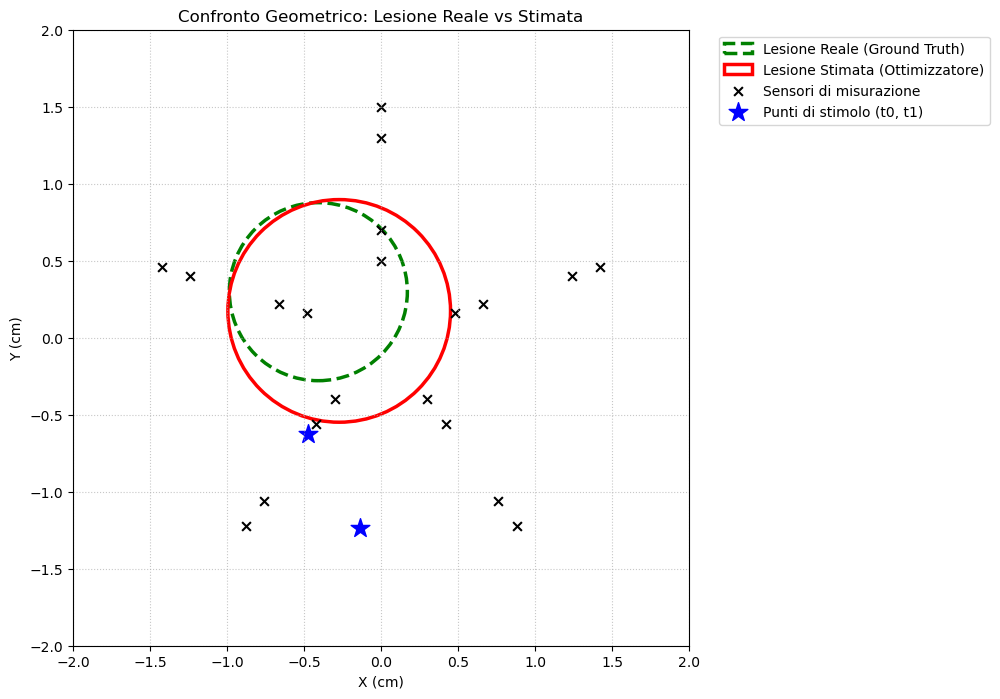

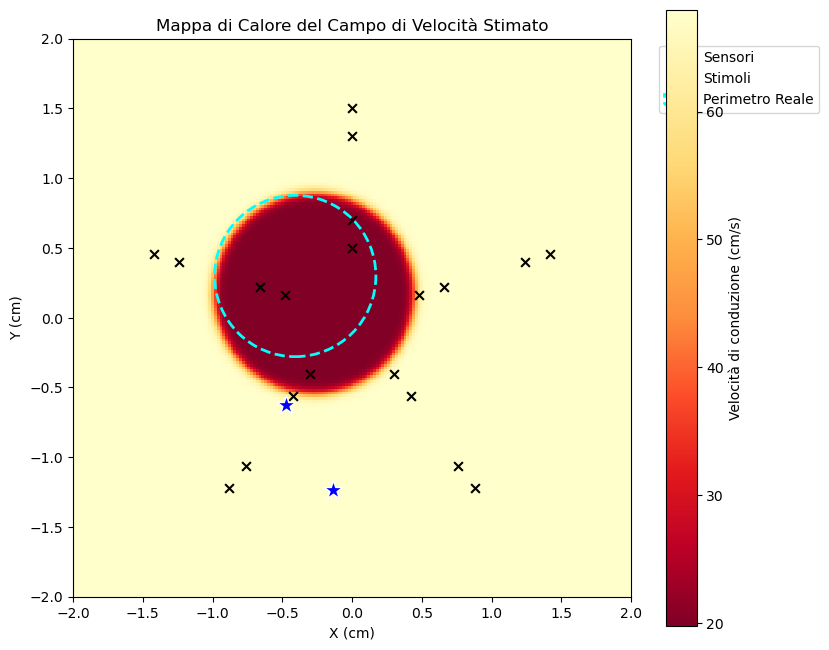

In [49]:
# Impacchetta le variabili per passarle alle funzioni di plot
target_reale_pack = [true_x, true_y, true_r]
target_stimato_pack = [pred_x, pred_y, pred_r]
impulsi_pack = [x_0, y_0, x_1, y_1]

# Richiama il Grafico Geometrico
plot_geometric_solution(
    true_target=target_reale_pack, 
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel
)

# Richiama la Mappa di Calore (assicurati che EST_V_BASE e EST_V_SLOW siano disponibili nel namespace globale)
plot_velocity_heatmap(
    true_target=target_reale_pack,
    pred_target=target_stimato_pack, 
    impulses=impulsi_pack, 
    sensors_indices=meas_indices_vel, 
    X_mesh=X_mesh_vel, 
    Y_mesh=Y_mesh_vel, 
    v_base=EST_V_BASE, 
    v_slow=EST_V_SLOW
)